# Top-20 fragment window analysis

Load the raw 15–40-residue window predictions, report the highest-sigma window for each fragment, and visualize each fragment's sigma-score distribution.

In [7]:
from pathlib import Path
import textwrap

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["font.family"] = "monospace"
plt.rcParams["pdf.fonttype"] = 42

WINDOW_MIN_LENGTH = 15
WINDOW_MAX_LENGTH = 40


def repo_root_from_here() -> Path:
    here = Path.cwd().resolve()
    for path in (here, *here.parents):
        if (path / "window_sequence_analysis").is_dir():
            return path
    raise FileNotFoundError("Could not locate the repository root.")


def latest_raw_predictions(results_dir: Path) -> Path:
    candidates = list((results_dir / "runs").glob("*/raw_window_predictions.csv"))
    if not candidates:
        raise FileNotFoundError(f"No raw window predictions found under {results_dir}")
    return max(candidates, key=lambda path: path.stat().st_mtime_ns)


ROOT = repo_root_from_here()
DATA_DIR = ROOT / "data" / "skin_samples" / "top_fragments" / "top_20_sequences"
FRAGMENTS_CSV = DATA_DIR / "top_20_fragments_with_flanks.csv"
WINDOW_PREDICTIONS_CSV = latest_raw_predictions(DATA_DIR / "results")
TOP_WINDOWS_CSV = DATA_DIR / "top_windows.csv"

print("Fragments:", FRAGMENTS_CSV)
print("Window predictions:", WINDOW_PREDICTIONS_CSV)

Fragments: /mnt/c/Users/bioin/Documents/Peptide-Anti-microbial-Properties-Prediction/data/skin_samples/top_fragments/top_20_sequences/top_20_fragments_with_flanks.csv
Window predictions: /mnt/c/Users/bioin/Documents/Peptide-Anti-microbial-Properties-Prediction/data/skin_samples/top_fragments/top_20_sequences/results/runs/2026-10-14_17-29/raw_window_predictions.csv


In [8]:
def windows_per_sequence(length: int, min_length: int, max_length: int) -> int:
    upper = min(length, max_length)
    if upper < min_length:
        return 0
    return sum(length - window_length + 1 for window_length in range(min_length, upper + 1))


def attach_fragment_metadata(
    fragments: pd.DataFrame,
    predictions: pd.DataFrame,
) -> pd.DataFrame:
    required_fragment_columns = {
        "id",
        "parent_id",
        "parent_name",
        "cluster",
        "DNGC",
        "sequence_type",
        "sequence",
    }
    required_prediction_columns = {
        "id",
        "window_start_0based",
        "window_end_0based_exclusive",
        "sigma",
        "p_amp",
    }
    if missing := sorted(required_fragment_columns - set(fragments.columns)):
        raise ValueError(f"Fragment CSV is missing columns: {missing}")
    if missing := sorted(required_prediction_columns - set(predictions.columns)):
        raise ValueError(f"Prediction CSV is missing columns: {missing}")

    parts: list[pd.DataFrame] = []
    offset = 0
    for source_row, fragment in fragments.reset_index(drop=True).iterrows():
        sequence = str(fragment["sequence"])
        count = windows_per_sequence(len(sequence), WINDOW_MIN_LENGTH, WINDOW_MAX_LENGTH)
        part = predictions.iloc[offset : offset + count].copy()
        if count and not part["id"].astype(str).eq(str(fragment["id"])).all():
            raise ValueError(f"Prediction order does not match fragment row {source_row}.")
        part["source_row"] = source_row
        part["fragment_id"] = fragment["id"]
        part["parent_id"] = fragment["parent_id"]
        part["parent_name"] = fragment["parent_name"]
        part["cluster"] = fragment["cluster"]
        part["DNGC"] = fragment["DNGC"]
        part["sequence_type"] = fragment["sequence_type"]
        starts = part["window_start_0based"].astype(int)
        ends = part["window_end_0based_exclusive"].astype(int)
        part["window_sequence"] = [sequence[start:end] for start, end in zip(starts, ends, strict=True)]
        parts.append(part)
        offset += count
    if offset != len(predictions):
        raise ValueError(f"Mapped {offset:,} of {len(predictions):,} prediction rows.")
    return pd.concat(parts, ignore_index=True)


fragments = pd.read_csv(FRAGMENTS_CSV)
raw_predictions = pd.read_csv(WINDOW_PREDICTIONS_CSV)
window_predictions = attach_fragment_metadata(fragments, raw_predictions)

fragment_order = fragments["id"].drop_duplicates().tolist()
fragment_rank = {fragment_id: rank for rank, fragment_id in enumerate(fragment_order, start=1)}
window_predictions["fragment_rank"] = window_predictions["fragment_id"].map(fragment_rank)
window_predictions["window_length"] = (
    window_predictions["window_end_0based_exclusive"]
    - window_predictions["window_start_0based"]
)

top_windows = (
    window_predictions.sort_values("sigma", ascending=False, kind="mergesort")
    .drop_duplicates("fragment_id")
    .sort_values("fragment_rank")
)
top_window_table = top_windows[
    [
        "fragment_rank",
        "fragment_id",
        "parent_id",
        "parent_name",
        "sequence_type",
        "window_sequence",
        "window_length",
        "window_start_0based",
        "window_end_0based_exclusive",
        "sigma",
        "p_amp",
    ]
].reset_index(drop=True)

top_window_table.to_csv(TOP_WINDOWS_CSV, index=False)
print(f"Top window for {len(top_window_table)} fragments")
print(f"Wrote {TOP_WINDOWS_CSV}")
display(top_window_table.style.hide(axis="index").format({"sigma": "{:.4f}", "p_amp": "{:.4f}"}))

Top window for 20 fragments
Wrote /mnt/c/Users/bioin/Documents/Peptide-Anti-microbial-Properties-Prediction/data/skin_samples/top_fragments/top_20_sequences/top_windows.csv


fragment_rank,fragment_id,parent_id,parent_name,sequence_type,window_sequence,window_length,window_start_0based,window_end_0based_exclusive,sigma,p_amp
1,sp|P49913|CAMP_HUMAN-135,sp|P49913|CAMP_HUMAN,Cathelicidin antimicrobial peptide,before_sequence,FKRIVQRIKDFLRNLVPR,18,25,43,3.6964,1.0000
2,sp|Q9HCE5|MET14_HUMAN-412,sp|Q9HCE5|MET14_HUMAN,N(6)-adenosine-methyltransferase non-catalytic subunit METTL14,before_sequence,RSNFRGERGGFRGGRGGAHRG,21,29,50,3.6920,1.0000
3,sp|Q15334|L2GL1_HUMAN-646,sp|Q15334|L2GL1_HUMAN,Lethal(2) giant larvae protein homolog 1,before_sequence,SRVKSLKKSLRQSFRR,16,15,31,3.8862,1.0000
4,sp|P62805|H4_HUMAN-1,sp|P62805|H4_HUMAN,Histone H4,existing_sequence,HRKVLRDNIQGITKPAIRRLARR,23,18,41,3.3038,1.0000
5,sp|Q9Y343|SNX24_HUMAN-32,sp|Q9Y343|SNX24_HUMAN,Sorting nexin-24,before_sequence,KHFVEKRYSEFHALHKKLKKCIK,23,10,33,3.5579,1.0000
6,sp|Q9NY12|GAR1_HUMAN-159,sp|Q9NY12|GAR1_HUMAN,H/ACA ribonucleoprotein complex subunit 1,before_sequence,GRGGGRGGGFRGGRGGGGGGFRGGRGGGFRGR,32,35,67,3.1079,1.0000
7,sp|Q9NX24|NHP2_HUMAN-36,sp|Q9NX24|NHP2_HUMAN,H/ACA ribonucleoprotein complex subunit 2,before_sequence,SRRLTRKLYKCIKKAVKQ,18,14,32,3.8701,1.0000
8,sp|P62910|RL32_HUMAN-1,sp|P62910|RL32_HUMAN,Large ribosomal subunit protein eL32,existing_sequence,IKRNWRKPRGIDNRVRRRFKGQI,23,30,53,2.7797,0.9965
9,sp|Q9Y5S9|RBM8A_HUMAN-154,sp|Q9Y5S9|RBM8A_HUMAN,RNA-binding protein 8A,before_sequence,WCFVRGPPKGKRRGGRR,17,4,21,2.7819,0.9965
10,sp|P26373|RL13_HUMAN-2,sp|P26373|RL13_HUMAN,Large ribosomal subunit protein eL13,before_sequence,LKPHFHKDWQRRVATWFNQPARKIRR,26,9,35,3.0349,1.0000


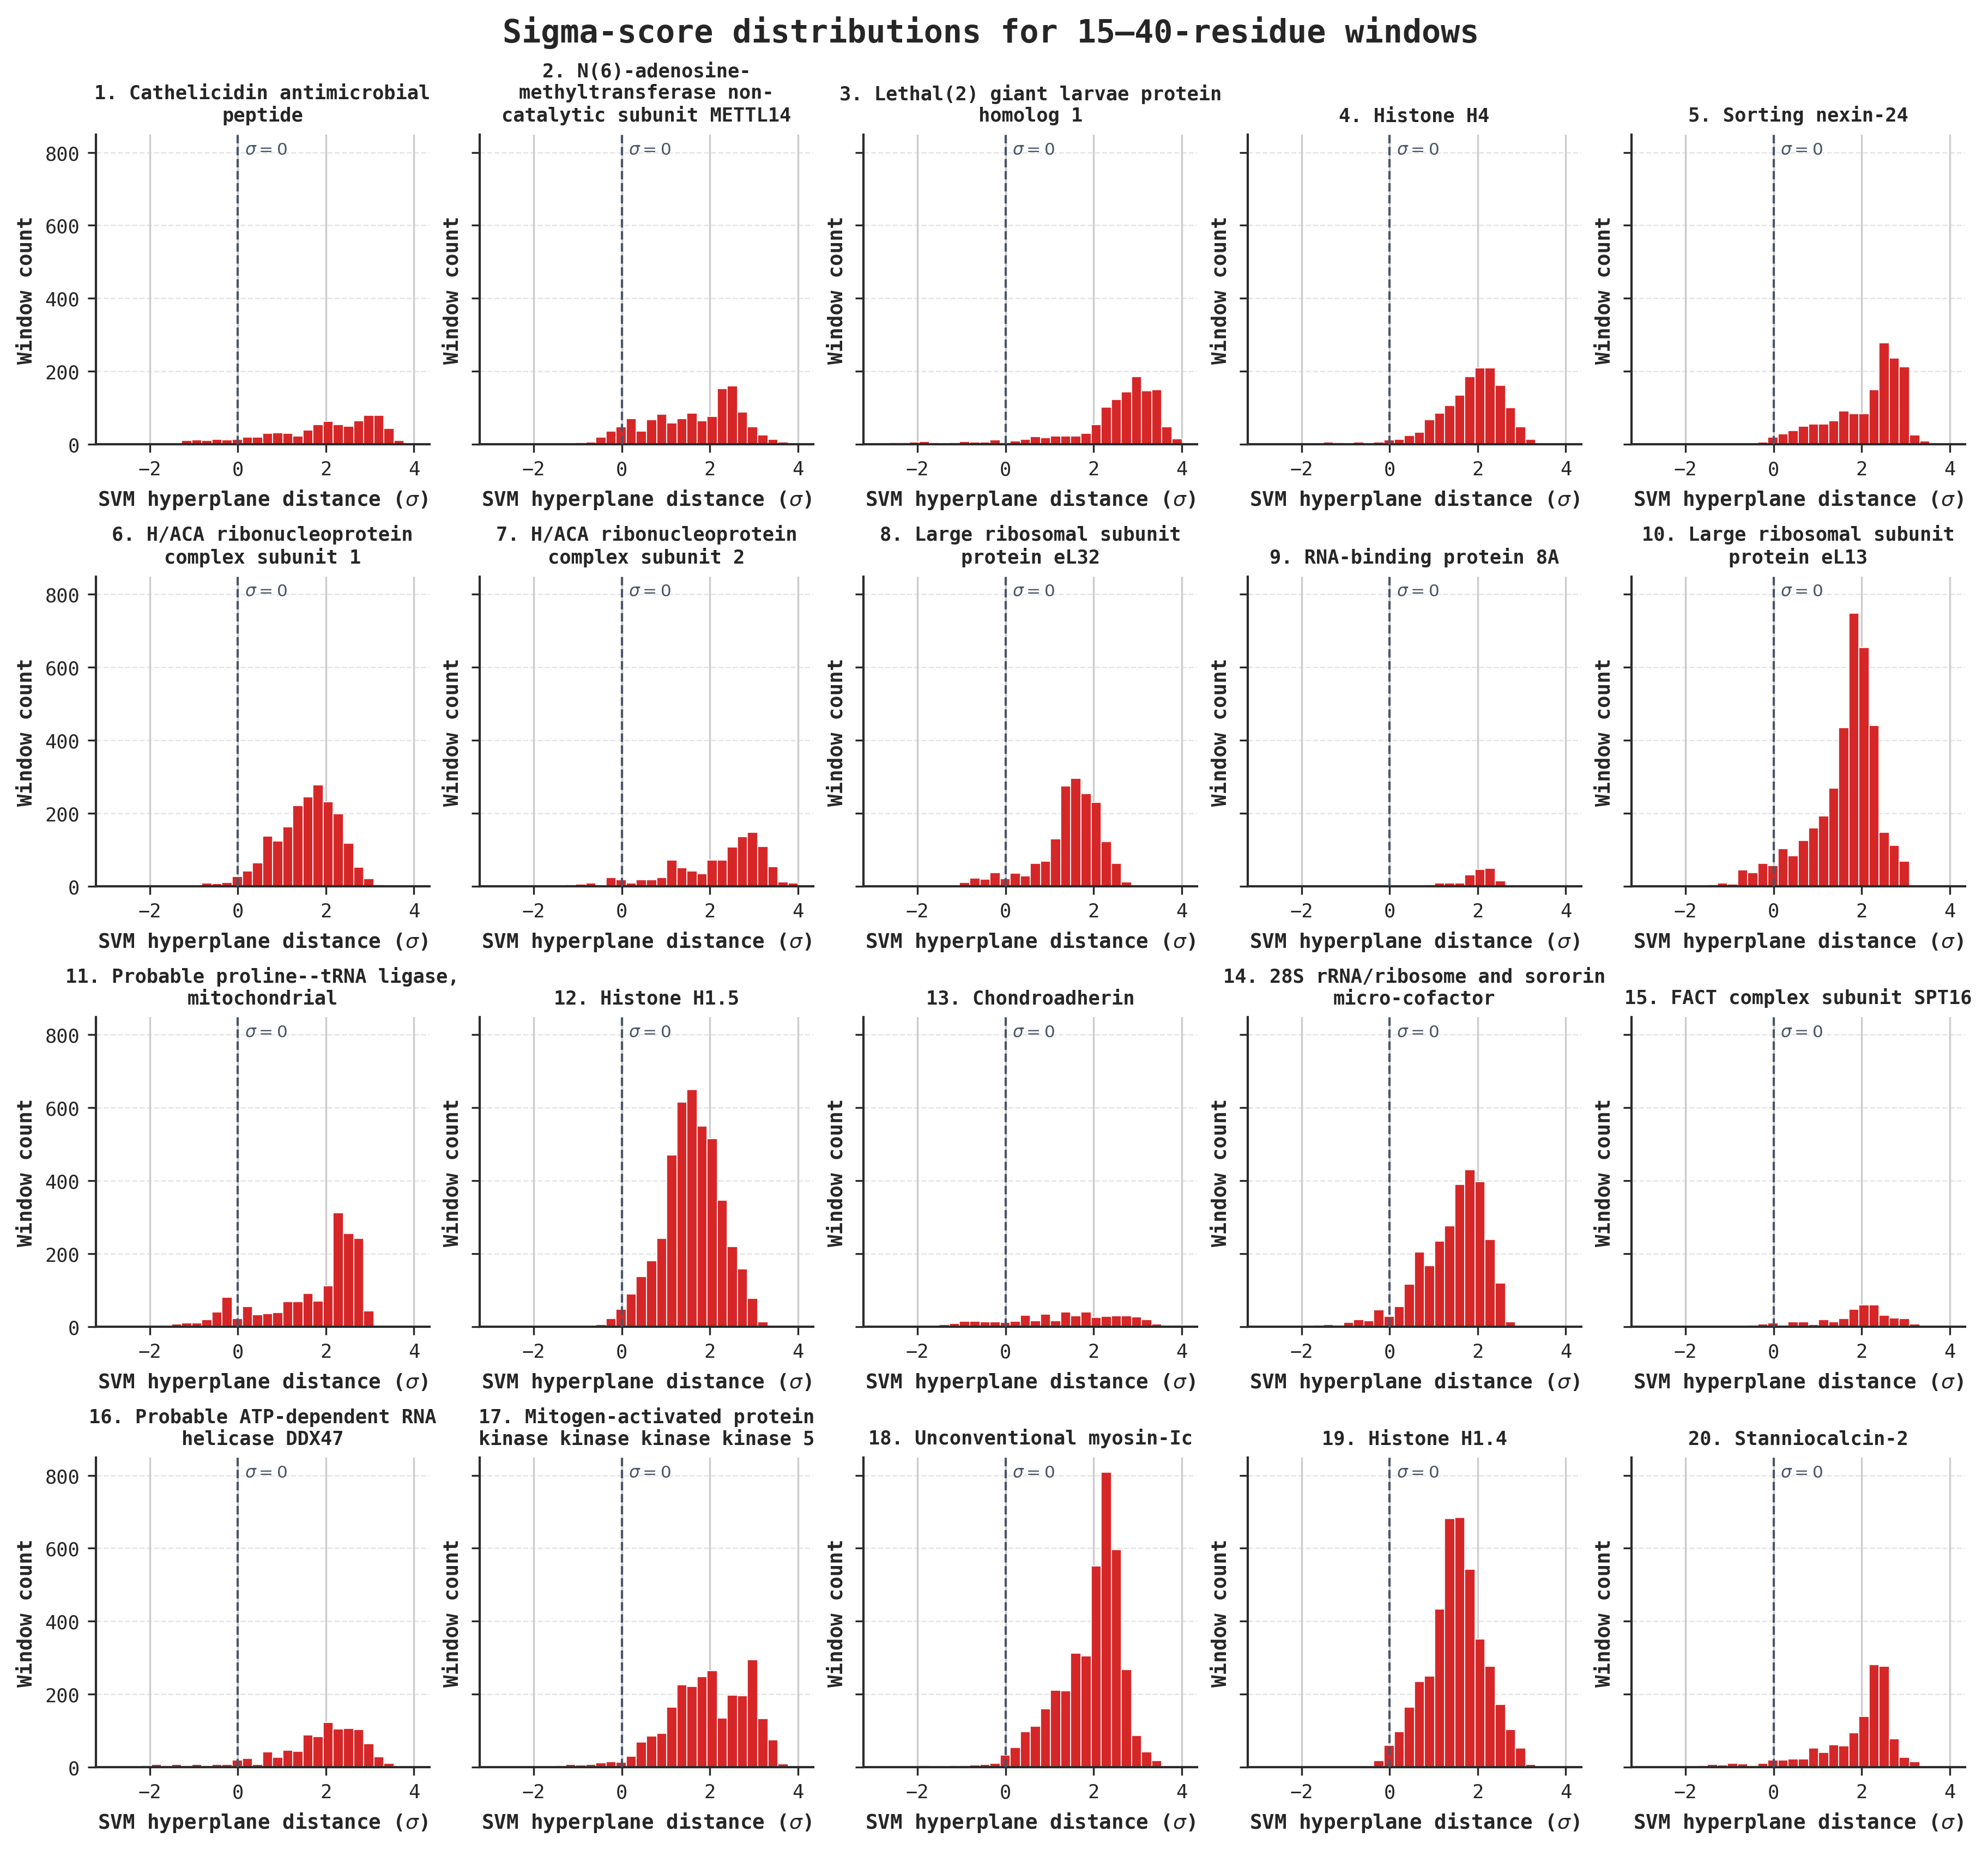

In [9]:
PANEL_COLOR = "#d62728"
SPINE_COLOR = "#2b2b2b"
ZERO_LINE_COLOR = "#4A5568"


def fragment_label(rank: int, name: str) -> str:
    return f"{rank}. " + "\n".join(textwrap.wrap(name, width=30))


def style_distribution_axis(axis: plt.Axes) -> None:
    axis.set_axisbelow(True)
    axis.spines["top"].set_visible(False)
    axis.spines["right"].set_visible(False)
    axis.spines["left"].set_color(SPINE_COLOR)
    axis.spines["bottom"].set_color(SPINE_COLOR)
    axis.grid(axis="y", linestyle="--", linewidth=0.6, alpha=0.5, zorder=0)
    axis.tick_params(axis="both", labelsize=8.5, length=3.5, width=0.8)
    axis.tick_params(axis="x", labelbottom=True)
    axis.set_xlabel(r"SVM hyperplane distance ($\sigma$)", fontsize=9, fontweight="bold")
    axis.set_ylabel("Window count", fontsize=9, fontweight="bold")


def label_zero_line(axis: plt.Axes) -> None:
    axis.axvline(0, color=ZERO_LINE_COLOR, linewidth=1.0, linestyle="--", zorder=3)
    axis.annotate(
        r"$\sigma = 0$",
        xy=(0, 1),
        xycoords=("data", "axes fraction"),
        xytext=(3, -3),
        textcoords="offset points",
        ha="left",
        va="top",
        fontsize=7.5,
        color=ZERO_LINE_COLOR,
    )


fragment_count = len(fragment_order)
column_count = 5
row_count = int(np.ceil(fragment_count / column_count))
figure, axes = plt.subplots(
    row_count,
    column_count,
    figsize=(12, 2.8 * row_count),
    dpi=300,
    sharex=True,
    sharey=True,
    constrained_layout=True,
)
finite_sigma = window_predictions["sigma"].dropna().to_numpy(dtype=float)
bin_edges = np.linspace(finite_sigma.min(), finite_sigma.max(), 31)

for fragment_id, axis in zip(fragment_order, axes.flat, strict=False):
    group = window_predictions.loc[window_predictions["fragment_id"] == fragment_id]
    scores = group["sigma"].dropna().to_numpy(dtype=float)
    rank = fragment_rank[fragment_id]
    name = str(group["parent_name"].iloc[0])
    style_distribution_axis(axis)
    axis.hist(
        scores,
        bins=bin_edges,
        color=PANEL_COLOR,
        edgecolor="white",
        linewidth=0.4,
        zorder=2,
    )
    label_zero_line(axis)
    axis.set_title(fragment_label(rank, name), fontsize=8.5, fontweight="bold", pad=6)

for axis in axes.flat[fragment_count:]:
    axis.set_visible(False)

figure.suptitle(
    "Sigma-score distributions for 15–40-residue windows",
    fontsize=14,
    fontweight="bold",
)
plt.show()

## Highest-sigma fragment window per top cluster

For each of the top 10 clusters, select the window with the highest SVM sigma score. Name and DNGC describe that window's parent sequence.

In [10]:
TOP_CLUSTER_ORDER = [30, 106, 44, 22, 43, 65, 8, 27, 15, 12]
CLUSTER_DATA_DIR = ROOT / "data" / "skin_samples" / "top_fragments" / "top_10_clusters"
CLUSTER_FRAGMENTS_CSV = CLUSTER_DATA_DIR / "fragment_sequences_with_flanks.csv"
CLUSTER_WINDOW_PREDICTIONS_CSV = latest_raw_predictions(CLUSTER_DATA_DIR / "results")

cluster_fragments = pd.read_csv(CLUSTER_FRAGMENTS_CSV)
cluster_raw_predictions = pd.read_csv(CLUSTER_WINDOW_PREDICTIONS_CSV)
cluster_window_predictions = attach_fragment_metadata(
    cluster_fragments,
    cluster_raw_predictions,
)
cluster_window_predictions["window_length"] = (
    cluster_window_predictions["window_end_0based_exclusive"]
    - cluster_window_predictions["window_start_0based"]
)

cluster_order = {cluster: rank for rank, cluster in enumerate(TOP_CLUSTER_ORDER)}
cluster_top_windows = (
    cluster_window_predictions.sort_values("sigma", ascending=False, kind="mergesort")
    .drop_duplicates("cluster")
    .assign(_cluster_order=lambda frame: frame["cluster"].map(cluster_order))
    .sort_values("_cluster_order", kind="mergesort")
)
if set(cluster_top_windows["cluster"]) != set(TOP_CLUSTER_ORDER):
    raise ValueError("Window results do not contain the expected top 10 clusters.")

cluster_window_table = cluster_top_windows[
    ["cluster", "parent_name", "DNGC", "window_length", "sigma"]
].rename(
    columns={
        "parent_name": "name",
        "window_length": "top fragment length",
        "sigma": "top fragment sigma",
    }
)
cluster_window_table["cluster"] = cluster_window_table["cluster"].map(
    lambda value: f"Cluster {int(value)}"
)
cluster_window_table = cluster_window_table.reset_index(drop=True)

cluster_table_style = (
    cluster_window_table.style.hide(axis="index")
    .format({"DNGC": "{:.4f}", "top fragment sigma": "{:.4f}"})
    .set_properties(
        **{
            "font-family": "monospace",
            "border": "1px solid #A6A6A6",
            "padding": "8px",
        }
    )
    .set_table_styles(
        [
            {
                "selector": "th",
                "props": [
                    ("background-color", "#D9D9D9"),
                    ("font-family", "monospace"),
                    ("font-weight", "bold"),
                    ("border", "1px solid #A6A6A6"),
                    ("padding", "8px"),
                ],
            },
            {"selector": "table", "props": [("border-collapse", "collapse")]},
        ]
    )
)
display(cluster_table_style)

cluster,name,DNGC,top fragment length,top fragment sigma
Cluster 30,Cathelicidin antimicrobial peptide,1.5798,18,3.6964
Cluster 106,Histone H1.1,1.0057,22,2.2368
Cluster 44,Endoplasmin,0.8447,22,2.9137
Cluster 22,Probable ATP-dependent RNA helicase DDX47,1.1410,26,3.5117
Cluster 43,Zinc finger protein 518A,0.5845,29,2.2904
Cluster 65,LLGL scribble cell polarity complex component 2,0.7773,16,3.8862
Cluster 8,Protein disulfide-isomerase A6,0.6728,23,3.0975
Cluster 27,Protein DEK,0.5310,20,3.4733
Cluster 15,Translationally-controlled tumor protein,0.4243,15,3.4299
Cluster 12,Serine/threonine-protein phosphatase 2A 56 kDa regulatory subunit epsilon isoform,0.4751,21,3.2511
